# Benchmarks — join, optimización y escalabilidad

Proyecto: Detección temprana de pérdida de paridad de USDC en Binance (eventos Terra, FTX y SVB, 2022–2023).

Este notebook **lee** las salidas crudas que ya están en `benchmarks/resultados/` y las muestra en tablas y gráficos. **No vuelve a correr ningún benchmark** y no usa Spark ni HDFS.

| Sección | Qué muestra | Fuente |
|---|---|---|
| 1 | Broadcast join frente a sort-merge join (Pedido 2) | `pedido2_run.log` |
| 2 | `quality.py` original frente a `quality_opt.py` y unión con broadcast (Pedido 5) | tabla de `benchmarks/resultados/README.md` |
| 3 | Escalabilidad de la limpieza y la unión en una sola máquina, 10x a 200x (Pedido de escalabilidad 3.7) | `escalabilidad/*_resumen.txt` |
| 4 | Escalabilidad de aggTrades, local frente a clúster, 1x a 5x (Pedido 9) | `escalabilidad_aggtrades/*_resumen.txt` |

**Cómo leer las cifras.** Las cifras oficiales son las del informe de cada pedido. Los tiempos de estas tablas son los que contiene cada log: algunos miden el proceso completo (incluye el arranque de Spark) y otros miden el total dentro del script, así que **no son comparables columna a columna entre secciones**. Cada escala se midió una sola vez, salvo donde se indican repeticiones; con una sola corrida no hay intervalo de confianza. En el Pedido 9 el 1x y el 2x se repitieron tres veces; el 3x y el 5x del clúster se corrieron una sola vez.

In [1]:
import re, json
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

CWD = Path.cwd()
REPO = CWD.parent if CWD.name == "notebooks" else CWD
RES = REPO / "benchmarks" / "resultados"
assert RES.is_dir(), f"No se encuentra {RES}. Ejecuta el notebook desde notebooks/ de un clon del repositorio."
print("Resultados leídos desde:", RES)

Resultados leídos desde: /home/marlon/pedido12/stablecoin-depeg-detection/benchmarks/resultados


## 1. Broadcast join frente a sort-merge join (Pedido 2)

`src/benchmark_join.py` unió la tabla principal de klines (USDCUSDT, BTCUSDC y BTCUSDT: 44 623 filas) con la tabla de los sustitutos (BUSDUSDT y BTCBUSD: 7 296 filas). Se hicieron 6 corridas de cada variante y **la primera, de calentamiento, se descarta**. «Antes» es el sort-merge join (`autoBroadcastJoinThreshold = -1`, AQE desactivado); «después» es el broadcast join explícito. El log trae además los planes físicos (`pedido2_explain_output.txt`) y la comprobación de que ambas variantes dan el mismo resultado (`pedido2_verif.log`).

variante  broadcast join  sort-merge join
corrida                                  
0                 33.004           84.495
1                 16.492           75.976
2                 16.666           91.152
3                 13.617           85.242
4                 13.156           85.322
5                 15.605           74.208

                 count    mean     min     max
variante                                      
broadcast join       5  15.107  13.156  16.666
sort-merge join      5  82.380  74.208  91.152

El broadcast join es 5.5 veces más rápido que el sort-merge join (promedio de las 5 corridas válidas).


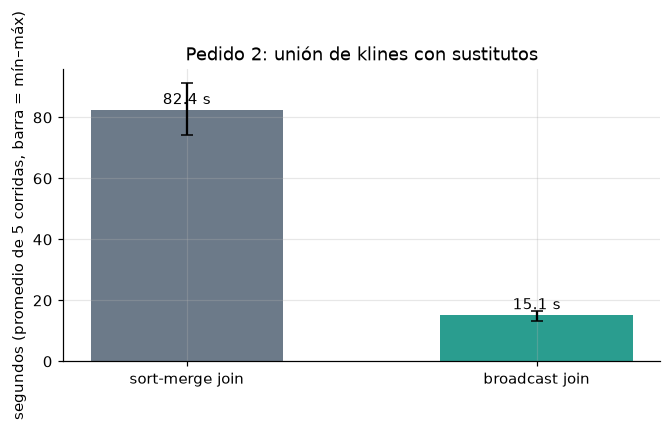

In [2]:
texto = (RES / "pedido2_run.log").read_text(errors="replace")
filas = []
for var, nombre in [("antes", "sort-merge join"), ("despues", "broadcast join")]:
    for m in re.finditer(rf"\[{var}\] corrida (\d+): ([0-9.]+)s", texto):
        filas.append(dict(variante=nombre, corrida=int(m.group(1)), segundos=float(m.group(2))))
p2 = pd.DataFrame(filas)
p2["valida"] = p2["corrida"] > 0          # la corrida 0 es de calentamiento
print(p2.pivot(index="corrida", columns="variante", values="segundos").to_string())

valid = p2[p2.valida].groupby("variante")["segundos"].agg(["count", "mean", "min", "max"]).round(3)
print()
print(valid.to_string())
factor = valid.loc["sort-merge join", "mean"] / valid.loc["broadcast join", "mean"]
print(f"\nEl broadcast join es {factor:.1f} veces más rápido que el sort-merge join (promedio de las 5 corridas válidas).")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
medias = valid["mean"].reindex(["sort-merge join", "broadcast join"])
barras = ax.bar(medias.index, medias.values, color=["#6c7a89", "#2a9d8f"], width=0.55)
ax.errorbar(medias.index, medias.values, yerr=[medias.values - valid["min"].reindex(medias.index).values, valid["max"].reindex(medias.index).values - medias.values], fmt="none", ecolor="black", capsize=4)
for b, v in zip(barras, medias.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.1f} s", ha="center")
ax.set_ylabel("segundos (promedio de 5 corridas, barra = mín–máx)")
ax.set_title("Pedido 2: unión de klines con sustitutos")
plt.tight_layout(); plt.show()

## 2. Versión original frente a optimizada (Pedido 5)

Los tiempos salen de la tabla de `benchmarks/resultados/README.md`. Las réplicas de 10x y 100x se generaron con `src/replicate_raw.py` en `hdfs:///datalake/benchmark/`. `quality.py` es la limpieza original; `quality_opt.py` es la versión optimizada (ventana por símbolo o por mes, y `shuffle.partitions` ajustado); «unión» es el join con broadcast (`src/join_broadcast_solo.py`). Los intentos fallidos no entran en las cifras.

In [3]:
readme = (RES / "README.md").read_text()
tabla = []
for linea in readme.splitlines():
    if not linea.startswith("| `"):
        continue
    celdas = [c.strip() for c in linea.strip().strip("|").split("|")]
    if len(celdas) != 3:
        continue
    log, que, tiempo = celdas
    log = log.strip("`")
    if not re.match(r"(q|qopt|j|jopt)_", log):
        continue
    m = re.search(r"(?:(\d+) min )?([0-9.]+) s", tiempo)
    seg = (int(m.group(1) or 0) * 60 + float(m.group(2))) if m else None
    escala = re.search(r"_(\d+)x", log)
    tabla.append(dict(log=log, descripcion=que.replace("`", ""), escala=int(escala.group(1)) if escala else None, segundos=seg))
p5 = pd.DataFrame(tabla)
print(p5.to_string(index=False))

                           log                                                                                                              descripcion  escala  segundos
                   q_1x_r2.log                                                                                                  quality.py original, 1x       1     150.6
                  q_10x_r2.log                                                                                                 quality.py original, 10x      10     518.8
                   j_1x_r2.log                                                                                                  unión con broadcast, 1x       1      76.9
                  j_10x_r2.log                                                                                                 unión con broadcast, 10x      10     144.3
           qopt_1x_simbolo.log                                                                                  quality_opt.py, 1x, ventana por símbol

        quality.py original (s)  quality_opt.py, ventana por símbolo (s)  unión con broadcast (s)  optimizada / original
escala                                                                                                                  
1                         150.6                                    190.0                     76.9                    1.3
10                        518.8                                    351.3                    144.3                    0.7

quality.py original: al pasar de 1x a 10x el tiempo se multiplica por 3.44
quality_opt.py (símbolo): al pasar de 1x a 10x el tiempo se multiplica por 1.85
unión con broadcast: al pasar de 1x a 10x el tiempo se multiplica por 1.88
quality_opt.py a 100x (ventana por mes, shuffle.partitions=64): 2005 s


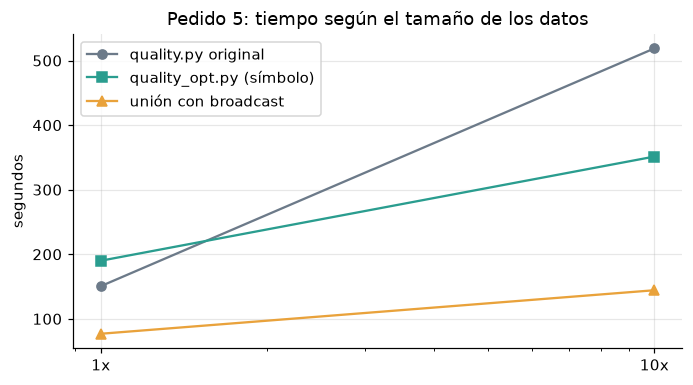

In [4]:
orig = p5[p5.log.str.startswith("q_")].set_index("escala")["segundos"]
opt_simbolo = p5[p5.log.isin(["qopt_1x_simbolo.log", "qopt_10x_simbolo.log"])].set_index("escala")["segundos"]
union = p5[p5.log.str.startswith("j_")].set_index("escala")["segundos"]

cmp = pd.DataFrame({"quality.py original (s)": orig, "quality_opt.py, ventana por símbolo (s)": opt_simbolo, "unión con broadcast (s)": union}).dropna(how="all")
cmp["optimizada / original"] = (cmp.iloc[:, 1] / cmp.iloc[:, 0]).round(2)
print(cmp.round(1).to_string())
print()
for nombre, s in [("quality.py original", orig), ("quality_opt.py (símbolo)", opt_simbolo), ("unión con broadcast", union)]:
    if 1 in s.index and 10 in s.index:
        print(f"{nombre}: al pasar de 1x a 10x el tiempo se multiplica por {s[10] / s[1]:.2f}")
r100 = p5[p5.log == "qopt_100x_mes_sp64_rw0.log"]["segundos"]
if len(r100):
    print(f"quality_opt.py a 100x (ventana por mes, shuffle.partitions=64): {r100.iloc[0]:.0f} s")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for nombre, s, color, mk in [("quality.py original", orig, "#6c7a89", "o"), ("quality_opt.py (símbolo)", opt_simbolo, "#2a9d8f", "s"), ("unión con broadcast", union, "#e9a23b", "^")]:
    s = s.sort_index()
    ax.plot(s.index, s.values, marker=mk, color=color, label=nombre)
ax.set_xscale("log"); ax.set_xticks([1, 10]); ax.set_xticklabels(["1x", "10x"])
ax.set_ylabel("segundos"); ax.set_title("Pedido 5: tiempo según el tamaño de los datos")
ax.legend(); plt.tight_layout(); plt.show()

## 3. Escalabilidad en una sola máquina (10x a 200x)

Corridas con `--master local[*]` en el master (2 vCPU, 3 915 MB de RAM, 974 MiB de swap), con `bench_local.sh`, que además muestrea la memoria cada 5 s. Cada archivo `*_resumen.txt` guarda el código de salida (**137 = el sistema operativo mató el proceso por falta de memoria**), los segundos reales y los máximos de memoria. Las escalas de 150x y 200x terminaron por falta de memoria: es el límite de una sola máquina, y se muestra tal cual.

In [5]:
patron_bloque = re.compile(r"=== RESUMEN (quality|join) \((orig|opt) (\d+)x local\[\*\].*?\)(.*?)(?=\n=== RESUMEN|\Z)", re.S)
filas = []
for f in sorted((RES / "escalabilidad").glob("local_*_resumen.txt")):
    for m in patron_bloque.finditer(f.read_text()):
        etapa, version, escala, cuerpo = m.group(1), m.group(2), int(m.group(3)), m.group(4)
        g = lambda rx: (re.search(rx, cuerpo).group(1) if re.search(rx, cuerpo) else None)
        real = g(r"real ([0-9.,]+)")
        filas.append(dict(
            etapa="limpieza" if etapa == "quality" else "unión",
            version="original" if version == "orig" else "optimizada",
            escala=escala,
            codigo_salida=int(g(r"exit: (\d+)")),
            segundos=float(real.replace(",", ".")) if real else None,
            rss_jvm_mb=int(g(r"max RSS JVM \(MB\): (\d+)")),
            ram_max_mb=int(g(r"max RAM usada \(MB\): (\d+)")),
            swap_max_mb=int(g(r"max swap \(MB\): (\d+)")),
            archivo=f.name))
esc = pd.DataFrame(filas).sort_values(["etapa", "version", "escala"]).reset_index(drop=True)
esc["resultado"] = esc.codigo_salida.map(lambda c: "OK" if c == 0 else ("SIGKILL por memoria" if c == 137 else f"código {c}"))
print(esc[["etapa", "version", "escala", "resultado", "segundos", "rss_jvm_mb", "ram_max_mb", "swap_max_mb"]].to_string(index=False))

   etapa    version  escala           resultado  segundos  rss_jvm_mb  ram_max_mb  swap_max_mb
limpieza optimizada      10                  OK   281.739        1742        3053          910
limpieza optimizada     100                  OK   934.318        2577        3858          974
limpieza optimizada     150 SIGKILL por memoria   342.504        3002        3910          974
limpieza optimizada     200 SIGKILL por memoria   247.042        2904        3896          974
limpieza   original      10                  OK   235.639        1574        3283          107
   unión optimizada      10                  OK    49.418        1252        2516          782
   unión optimizada     100                  OK   472.870        1447        2955          617
   unión   original      10                  OK    80.233        1020        2723          129


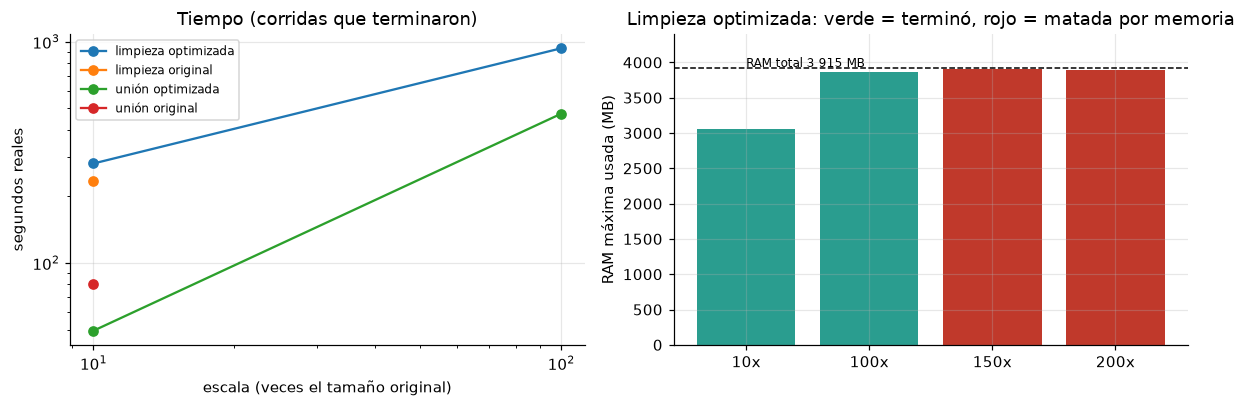

La limpieza optimizada terminó hasta 100x y falló desde 150x por memoria.
Factor de escala 10x -> 100x: el tiempo se multiplicó por 3.3 para 10 veces más datos.


In [6]:
ok = esc[esc.resultado == "OK"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (etapa, version), g in ok.groupby(["etapa", "version"]):
    axes[0].plot(g.escala, g.segundos, marker="o", label=f"{etapa} {version}")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("escala (veces el tamaño original)"); axes[0].set_ylabel("segundos reales")
axes[0].set_title("Tiempo (corridas que terminaron)"); axes[0].legend(fontsize=8)

lim = esc[(esc.etapa == "limpieza") & (esc.version == "optimizada")]
colores = ["#2a9d8f" if r == "OK" else "#c0392b" for r in lim.resultado]
axes[1].bar([f"{e}x" for e in lim.escala], lim.ram_max_mb, color=colores)
axes[1].axhline(3915, color="black", ls="--", lw=1); axes[1].text(0, 3935, "RAM total 3 915 MB", fontsize=8)
axes[1].set_ylabel("RAM máxima usada (MB)"); axes[1].set_ylim(0, 4400)
axes[1].set_title("Limpieza optimizada: verde = terminó, rojo = matada por memoria")
plt.tight_layout(); plt.show()

ult_ok = lim[lim.resultado == "OK"].escala.max()
primera_falla = lim[lim.resultado != "OK"].escala.min() if (lim.resultado != "OK").any() else None
print(f"La limpieza optimizada terminó hasta {ult_ok}x" + (f" y falló desde {primera_falla}x por memoria." if primera_falla else "."))
s10 = lim[lim.escala == 10].segundos.iloc[0]; s100 = lim[lim.escala == 100].segundos.iloc[0]
print(f"Factor de escala 10x -> 100x: el tiempo se multiplicó por {s100 / s10:.1f} para 10 veces más datos.")

## 4. Escalabilidad de aggTrades: local frente a clúster (Pedido 9)

`run_escalabilidad_aggtrades.sh` repitió la cadena completa de aggTrades (calidad, resumen horario y unión con klines) sobre réplicas del conjunto original (7 965 158 registros en 1x). Con la máquina sola, el 2x no termina (el sistema mata el proceso por memoria) y no se midió 3x ni 5x. «Local» es `--master local[*]` en el master; «clúster» es YARN con el master y el worker. Cada archivo `*_resumen.txt` trae el tiempo total, el desglose por etapa y los máximos de memoria. Las tres corridas de 1x del clúster con la configuración inicial (antes de dejar las librerías de Spark en HDFS con `spark.yarn.archive`) se conservan en `config_inicial_1x/` y **no entran en las tablas de abajo**.

In [7]:
filas = []
for f in sorted((RES / "escalabilidad_aggtrades").glob("*_resumen.txt")):
    m = re.match(r"(local|cluster)_(\d+)x_r(\d+)_resumen", f.stem)
    if not m:
        continue
    t = f.read_text()
    g = lambda rx: (re.search(rx, t).group(1) if re.search(rx, t) else None)
    reg = g(r"QC registros=([0-9,]+)")
    filas.append(dict(
        modo="local" if m.group(1) == "local" else "clúster",
        escala=int(m.group(2)), repeticion=int(m.group(3)),
        codigo_salida=int(g(r"exit: (\d+)")),
        segundos=int(g(r"segundos totales: (\d+)")),
        registros=int(reg.replace(",", "")) if reg else None,
        calidad_s=float(g(r"ETAPA calidad ([0-9.]+)")) if g(r"ETAPA calidad ([0-9.]+)") else None,
        resumen_horario_s=float(g(r"ETAPA resumen_horario ([0-9.]+)")) if g(r"ETAPA resumen_horario ([0-9.]+)") else None,
        union_s=float(g(r"ETAPA union_klines ([0-9.]+)")) if g(r"ETAPA union_klines ([0-9.]+)") else None,
        rss_spark_mb=int(g(r"max RSS Spark \(MB\): (\d+)")),
        ram_max_mb=int(g(r"max RAM usada \(MB\): (\d+)")),
        swap_max_mb=int(g(r"max swap \(MB\): (\d+)"))))
agg = pd.DataFrame(filas).sort_values(["modo", "escala", "repeticion"]).reset_index(drop=True)
agg["resultado"] = agg.codigo_salida.map(lambda c: "OK" if c == 0 else ("SIGKILL por memoria" if c == 137 else f"código {c}"))
print(agg[["modo", "escala", "repeticion", "resultado", "segundos", "registros", "calidad_s", "resumen_horario_s", "union_s", "ram_max_mb", "swap_max_mb"]].to_string(index=False))

   modo  escala  repeticion           resultado  segundos  registros  calidad_s  resumen_horario_s  union_s  ram_max_mb  swap_max_mb
clúster       1           1                  OK        58  7965158.0        9.8                4.0     20.3        2534          769
clúster       1           2                  OK        62  7965158.0       10.2                4.7     20.4        2815          770
clúster       1           3                  OK        61  7965158.0       10.1                4.2     18.8        2749          764
clúster       2           1                  OK        83 15930316.0       16.2                5.5     23.2        2277          973
clúster       2           2                  OK        61 15930316.0       12.6                5.4     20.0        2396          954
clúster       2           3                  OK        73 15930316.0       13.2                5.6     20.2        2566          938
clúster       3           1                  OK        63 23895474.0 

   modo  escala  corridas_ok  segundos_prom  segundos_min  segundos_max  registros  ram_max_mb  corridas_fallidas
clúster       1          3.0           60.3          58.0          62.0  7965158.0      2815.0                0.0
clúster       2          3.0           72.3          61.0          83.0 15930316.0      2566.0                0.0
clúster       3          1.0           63.0          63.0          63.0 23895474.0      2344.0                0.0
clúster       5          1.0           75.0          75.0          75.0 39825790.0      2366.0                0.0
  local       1          3.0           74.3          48.0          96.0  7965158.0      3900.0                0.0
  local       2          NaN            NaN           NaN           NaN        NaN         NaN                3.0



clúster: de 1x a 2x los datos se multiplican por 2 y el tiempo por 1.20
clúster: de 1x a 3x los datos se multiplican por 3 y el tiempo por 1.04
clúster: de 1x a 5x los datos se multiplican por 5 y el tiempo por 1.24


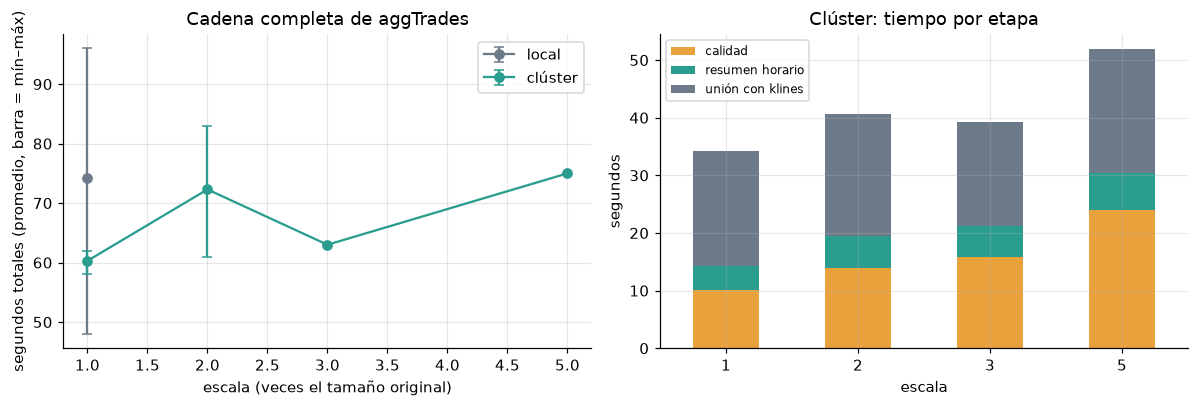

In [8]:
buenas = agg[agg.resultado == "OK"]
res = buenas.groupby(["modo", "escala"]).agg(corridas_ok=("segundos", "count"), segundos_prom=("segundos", "mean"), segundos_min=("segundos", "min"), segundos_max=("segundos", "max"),
                                             registros=("registros", "first"), ram_max_mb=("ram_max_mb", "max")).round(1).reset_index()
fallidas = agg[agg.resultado != "OK"].groupby(["modo", "escala"]).size().rename("corridas_fallidas").reset_index()
res = res.merge(fallidas, how="outer", on=["modo", "escala"]).fillna({"corridas_fallidas": 0}).sort_values(["modo", "escala"])
print(res.to_string(index=False))

# factor de escala respecto de 1x dentro de cada modo
print()
for modo, g in res.dropna(subset=["segundos_prom"]).groupby("modo"):
    g = g.set_index("escala")
    if 1 in g.index:
        for e in g.index[g.index > 1]:
            print(f"{modo}: de 1x a {e}x los datos se multiplican por {e} y el tiempo por {g.loc[e, 'segundos_prom'] / g.loc[1, 'segundos_prom']:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for modo, color in [("local", "#6c7a89"), ("clúster", "#2a9d8f")]:
    g = res[(res.modo == modo) & res.segundos_prom.notna()]
    axes[0].errorbar(g.escala, g.segundos_prom, yerr=[g.segundos_prom - g.segundos_min, g.segundos_max - g.segundos_prom], marker="o", color=color, capsize=3, label=modo)
axes[0].set_xlabel("escala (veces el tamaño original)"); axes[0].set_ylabel("segundos totales (promedio, barra = mín–máx)")
axes[0].set_title("Cadena completa de aggTrades"); axes[0].legend()

c = buenas[buenas.modo == "clúster"].groupby("escala")[["calidad_s", "resumen_horario_s", "union_s"]].mean()
c.plot(kind="bar", stacked=True, ax=axes[1], color=["#e9a23b", "#2a9d8f", "#6c7a89"], rot=0)
axes[1].set_xlabel("escala"); axes[1].set_ylabel("segundos"); axes[1].set_title("Clúster: tiempo por etapa")
axes[1].legend(["calidad", "resumen horario", "unión con klines"], fontsize=8)
plt.tight_layout(); plt.show()

## Cierre

Este notebook solo lee y resume resultados que ya existían. Si alguna cifra de aquí difiere de la del informe, vale la del informe del pedido correspondiente y la diferencia se debe reportar, no corregir. Para repetir un benchmark hay que usar los scripts del repositorio (`bench_*.sh`, `run_pedido5.sh`, `run_escalabilidad_aggtrades.sh`), que escriben solo en `hdfs:///datalake/benchmark/`.